# IV primer · why the naive win effect is biased, and how an instrument fixes it

Background for the planned win-effect notebook (`PLAN.md`, Phase 5 steps 4–5). The idea: the
game's random number generator decides whether a card is offered, so runs offered the card and runs
not offered it have the same players on average. Their difference in win rate is free of skill,
and dividing it by how much the offer raises picking gives the effect of picking. This is an
*instrumental variable* (IV) design, with the offer as the instrument.

Nothing here reads the run tables. It is a
simulation where we set the true effect ourselves, so we can see each estimator get it right or wrong.
The four quantities are the same ones `src/spirometry/wins.py` reports (naive, ITT, first stage, IV),
written out by hand and without the fixed effects, so nothing is hidden.

Sections:

0. **Setup**: the estimators, written as small helpers.
1. **The simulated game**: the true effect and the hidden skill, which the analyst can't see.
2. **The naive comparison**: how far off it is, and why.
3. **ITT, first stage, IV**: how the offer leads to the right answer.
4. **Many draws**: whether IV is right on average, and how noisy it is.
5. **Weak instruments**: what happens when a card is rarely picked.
6. **Confounding strength**: whether IV depends on how strong the skill effect is.
7. **When the instrument breaks**: an offer that isn't really random, or that acts on winning directly.
8. **Who the IV estimate is about**: a card that helps some players more than others.
9. **Mapping back to Spirometry**

How the words map:

| here | in Spirometry |
|---|---|
| `offered` (Z, the instrument) | card X shows up on one of the run's first 3 reward screens |
| `picked` (D, the treatment) | the run takes X |
| `won` (Y, the outcome) | the run wins |
| `skill` (U, hidden) | everything about the player that helps both picking well and winning |

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.5, "lines.markersize": 4,
})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_rows", 120)

TREATED_C, CONTROL_C, GREY = "#e8702a", "#2a6fdb", "#555555"   # same colors as 01 and 02

### The estimators

All four are slopes from a regression with an intercept, with HC1 (heteroskedasticity-robust)
errors, as in `wins.py`.

- **naive**: `won` on `picked`. Same as the difference in win rate between pickers and non-pickers.
- **ITT** (intent-to-treat): `won` on `offered`. Effect of the offer on winning, whether or not the
  run took the card.
- **first stage**: `picked` on `offered`. How much the offer moves picking.
- **IV**: ITT divided by the first stage (the Wald estimator). With one instrument and one
  treatment this is exactly two-stage least squares, and section 3 checks that.

The IV standard error is not the ratio of two standard errors, because the ITT and first stage are
estimated on the same runs and are correlated. It comes from the IV residual instead
(`won - a - b * picked`, using the real `picked`, not a fitted one).

In [2]:
def slope(x, y):
    """Slope of y on x (with intercept) and its HC1 standard error."""
    x = np.asarray(x, float); y = np.asarray(y, float); n = len(x)
    xc = x - x.mean(); sxx = (xc**2).sum()
    b = (xc * y).sum() / sxx
    e = y - y.mean() - b * xc
    se = np.sqrt(n / (n - 2) * (xc**2 * e**2).sum()) / sxx
    return b, se


def wald_iv(z, d, y):
    """IV estimate ITT / first stage, with a robust standard error from the IV residual."""
    z = np.asarray(z, float); d = np.asarray(d, float); y = np.asarray(y, float); n = len(z)
    zc = z - z.mean(); den = (zc * d).sum()
    b = (zc * y).sum() / den
    e = y - (y.mean() - b * d.mean()) - b * d
    se = np.sqrt(n / (n - 2) * (zc**2 * e**2).sum()) / abs(den)
    return b, se


def estimates(df):
    """All four quantities for one simulated dataset, plus the first-stage F."""
    naive, naive_se = slope(df.picked, df.won)
    itt, itt_se = slope(df.offered, df.won)
    fs, fs_se = slope(df.offered, df.picked)
    iv, iv_se = wald_iv(df.offered, df.picked, df.won)
    return dict(naive=naive, naive_se=naive_se, itt=itt, itt_se=itt_se,
                first_stage=fs, fs_se=fs_se, F=(fs / fs_se) ** 2, iv=iv, iv_se=iv_se)

## 1. The simulated game

Each run has a hidden `skill`, standard normal. Then:

1. **Offer.** Card X is offered with probability `offer_rate`. Skill plays no part: this is the RNG
   in the reward screens.
2. **Pick.** A run can only pick X if it was offered. If offered, it picks with probability
   `expit(pick_intercept + skill_on_pick * skill)`, so better players pick X more often.
3. **Win.** The win probability is `0.30 + tau * picked + skill_on_win * skill`, so skill helps
   winning directly, and picking X adds `tau` percentage points.

The true effect of picking is `tau = 0.10`. The analyst sees `offered`, `picked` and `won`, not `skill`.
The other arguments are switched on in sections 7 and 8.

In [3]:
def simulate(n=50_000, tau=0.10, het=0.0, skill_on_pick=1.0, skill_on_win=0.05,
             pick_intercept=-1.0, offer_rate=0.30, offer_skill=0.0, direct=0.0, seed=1):
    """One dataset of n runs.

    tau            true effect of picking X on the win probability
    het            the effect is tau + het * skill (0 = same effect for everyone)
    skill_on_pick  how strongly skill raises the chance of picking X when offered
    skill_on_win   how strongly skill raises the win probability on its own (the confounding)
    pick_intercept lower = X is picked less often when offered (weaker first stage)
    offer_rate     share of runs offered X
    offer_skill    > 0 breaks independence: skilled runs are offered X more often
    direct         > 0 breaks exclusion: being offered X changes winning without picking it
    """
    rng = np.random.default_rng(seed)
    skill = rng.standard_normal(n)
    offered = rng.random(n) < expit(logit(offer_rate) + offer_skill * skill)
    picked = offered & (rng.random(n) < expit(pick_intercept + skill_on_pick * skill))
    effect_i = tau + het * skill
    p_win = np.clip(0.30 + effect_i * picked + direct * offered + skill_on_win * skill, 0, 1)
    won = rng.random(n) < p_win
    return pd.DataFrame({"skill": skill, "offered": offered.astype(int),
                         "picked": picked.astype(int), "won": won.astype(int),
                         "effect_i": effect_i})


TAU = 0.10
df = simulate(seed=2)
df.head()

,skill,offered,picked,won,effect_i
0,0.189053,0,0,0,0.1
1,-0.522748,0,0,0,0.1
2,-0.413064,0,0,0,0.1
3,-2.441467,1,0,1,0.1
4,1.799707,0,0,0,0.1


## 2. The naive comparison

The obvious analysis: among all runs, compare the win rate of runs that picked X with runs that
didn't. The true answer is 0.10.

In [4]:
est = estimates(df)
win_pick = df.won[df.picked == 1].mean()
win_no = df.won[df.picked == 0].mean()
print(f"runs: {len(df):,}   offered: {df.offered.mean():.1%}   picked: {df.picked.mean():.1%}")
print(f"win rate, pickers {win_pick:.3f}  vs  non-pickers {win_no:.3f}")
print(f"naive effect  {est['naive']:.3f} ± {est['naive_se']:.3f}     (true effect {TAU:.3f})")

runs: 50,000   offered: 30.0%   picked: 9.0%
win rate, pickers 0.431  vs  non-pickers 0.301
naive effect  0.130 ± 0.008     (true effect 0.100)


The naive number lands well above 0.10. The extra part is skill, not the card: pickers are the runs
that were offered X **and** chose it, and better players choose it more. The table below shows
where the gap comes from.

The second column is the check that makes the instrument work. Runs that were offered X and runs
that weren't have the same average skill, because the offer is random. Runs that picked X and runs
that didn't do not.

In [5]:
balance = pd.DataFrame({
    "mean skill, group = picked":  df.groupby("picked").skill.mean(),
    "mean skill, group = offered": df.groupby("offered").skill.mean(),
}).rename_axis("group value (0 = no, 1 = yes)")
display(balance.round(3))

,"mean skill, group = picked","mean skill, group = offered"
"group value (0 = no, 1 = yes)",,
0,-0.055,0.004
1,0.584,-0.001


In real data we can't see skill, so we can't run this exact table. What we can do is check
variables that are fixed before the offer (ascension, character, build week) and see that they
look the same for offered and not-offered runs. That check is in the tooling as `strength.balance_check` (`balance_all` for every card).

## 3. ITT, first stage, IV

The offer is random, so its effect on winning can be measured without any skill contamination.
That effect is the ITT. It is smaller than the effect of picking, because only some of the offered
runs actually picked X. The first stage says how many. Dividing by it undoes the dilution.

    ITT = first stage × effect of picking     →     effect of picking = ITT / first stage

In [6]:
tab = pd.DataFrame({
    "estimate": [est["naive"], est["itt"], est["first_stage"], est["iv"]],
    "se":       [est["naive_se"], est["itt_se"], est["fs_se"], est["iv_se"]],
}, index=["naive (won ~ picked)", "ITT (won ~ offered)",
          "first stage (picked ~ offered)", "IV = ITT / first stage"])
tab["truth"] = [TAU, np.nan, np.nan, TAU]
display(tab.round(4))
print(f"first-stage F = {est['F']:.0f}   (the wins code flags F < 10 as weak)")
print(f"ITT / first stage = {est['itt'] / est['first_stage']:.4f}    IV = {est['iv']:.4f}")

,estimate,se,truth
naive (won ~ picked),0.1301,0.0077,0.1
ITT (won ~ offered),0.0265,0.0046,NaN
first stage (picked ~ offered),0.2988,0.0037,NaN
IV = ITT / first stage,0.0887,0.0152,0.1


first-stage F = 6383   (the wins code flags F < 10 as weak)
ITT / first stage = 0.0887    IV = 0.0887


The IV estimate is closer to 0.10 than the naive one, and its standard error is honest about how
far off a single draw can be. Section 4 repeats the draw many times.

### The same number as two-stage least squares

Two-stage least squares does it in two regressions: (1) predict `picked` from `offered`, (2) regress
`won` on that prediction. The prediction contains only the part of picking that came from the random
offer, which is why skill drops out. With one instrument the coefficient is the same as ITT / first stage.

One trap: the standard error printed by a plain second regression is not a valid IV standard error,
because it uses residuals built from the fitted `picked`. The right residual uses the real `picked`.
Here the two come out within a fraction of a percent of each other, because the effect is small next to the
noise in winning, so don't read the agreement as a reason to skip the correction: it can matter
with a larger effect or a weaker first stage.

In [7]:
Z = df.offered.to_numpy(float); D = df.picked.to_numpy(float); Y = df.won.to_numpy(float)

b1, a1 = np.polyfit(Z, D, 1)            # stage 1: picked ~ offered
D_hat = a1 + b1 * Z
b2, a2 = np.polyfit(D_hat, Y, 1)        # stage 2: won ~ predicted picked

def classical_se(resid, x):
    return np.sqrt((resid**2).sum() / (len(x) - 2)) / np.sqrt(((x - x.mean())**2).sum())

se_wrong = classical_se(Y - (a2 + b2 * D_hat), D_hat)   # what a plain second regression reports
se_right = classical_se(Y - (a2 + b2 * D), D_hat)       # residual built from the real picked

print(f"2SLS coefficient      {b2:.4f}    (ITT / first stage: {est['itt'] / est['first_stage']:.4f})")
print(f"se, second regression {se_wrong:.5f}    (residual from the fitted picked: not valid)")
print(f"se, IV residual       {se_right:.5f}    (robust version used above: {est['iv_se']:.5f})")

2SLS coefficient      0.0887    (ITT / first stage: 0.0887)
se, second regression 0.01514    (residual from the fitted picked: not valid)
se, IV residual       0.01510    (robust version used above: 0.01518)


Optional check against `pyfixest`, which the project already uses. The coefficient should match the
IV row above, and the standard error should be close to it.

In [8]:
try:
    import pyfixest as pf
    m = pf.feols("won ~ 1 | picked ~ offered", data=df, vcov="HC1")
    display(m.tidy())
except Exception as err:            # pyfixest missing, or the IV formula syntax differs
    print("pyfixest check skipped:", repr(err))

,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
Coefficient,,,,,,
Intercept,0.304358,0.002459,123.775930,0.000000e+00,0.299538,0.309177
picked,0.088720,0.015185,5.842667,5.168918e-09,0.058958,0.118483


## 4. Many draws

One dataset is one draw from the noise. Here we simulate 300 datasets of 20,000 runs each and look at
the spread of each estimator. Three things to read: whether IV is centered on 0.10, whether naive
is, and how often a 95% interval contains the truth.

In [9]:
def replicate(n_reps, seed0=1000, **kw):
    return pd.DataFrame([estimates(simulate(seed=seed0 + i, **kw)) for i in range(n_reps)])

rep = replicate(300, n=20_000)

def summarize(r, truth=TAU):
    out = {}
    for name in ["naive", "iv"]:
        covered = (r[name] - truth).abs() < 1.96 * r[name + "_se"]
        out[name] = dict(mean=r[name].mean(), sd_across_draws=r[name].std(),
                         mean_reported_se=r[name + "_se"].mean(), share_ci_covers_truth=covered.mean())
    return pd.DataFrame(out).T

display(summarize(rep).round(4))

,mean,sd_across_draws,mean_reported_se,share_ci_covers_truth
naive,0.1329,0.0124,0.0121,0.2367
iv,0.1032,0.0246,0.0236,0.9433


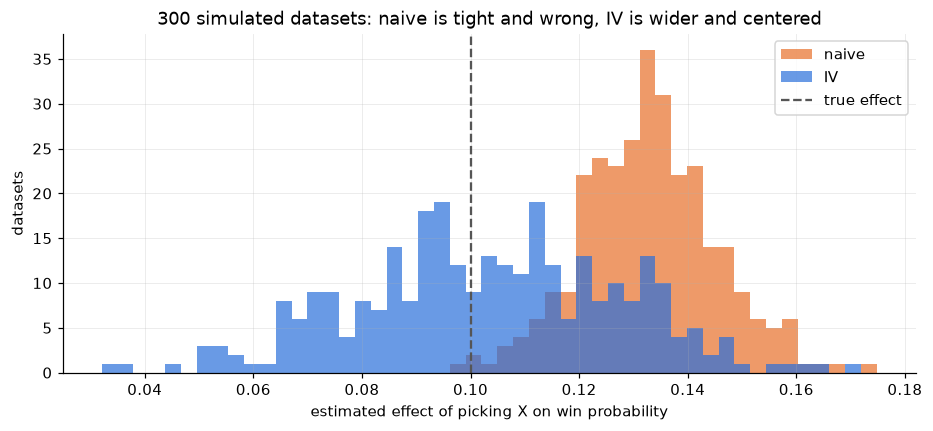

In [10]:
fig, ax = plt.subplots()
bins = np.linspace(min(rep.naive.min(), rep.iv.min()), max(rep.naive.max(), rep.iv.max()), 50)
ax.hist(rep.naive, bins=bins, color=TREATED_C, alpha=0.7, label="naive")
ax.hist(rep.iv, bins=bins, color=CONTROL_C, alpha=0.7, label="IV")
ax.axvline(TAU, color=GREY, ls="--", label="true effect")
ax.set_xlabel("estimated effect of picking X on win probability")
ax.set_ylabel("datasets")
ax.set_title("300 simulated datasets: naive is tight and wrong, IV is wider and centered")
ax.legend()
plt.show()

Naive has the smaller spread and is confidently wrong: its intervals contain the truth well under
95% of the time. IV is centered on 0.10, with a wider spread, and its intervals cover the truth about 95% of the time.
That trade is the whole story: IV pays in variance to get rid of bias.

## 5. Weak instruments

Now make X harder to pick, so fewer offered runs take it (lower `pick_intercept`), and use a smaller
sample of 5,000 runs. The first stage shrinks, and the IV divides by a small, noisy number.
The `F` column is the first-stage F statistic, `(coefficient / se)²`, which the wins code compares with 10.

In [11]:
rows = []
for a in [-1, -2, -3, -4, -5, -6]:
    r = replicate(300, n=5_000, pick_intercept=a)
    rows.append(dict(
        pick_intercept=a, first_stage=r.first_stage.median(), F=r.F.median(),
        share_F_below_10=(r.F < 10).mean(),
        naive_median=r.naive.median(), naive_p10=r.naive.quantile(.1), naive_p90=r.naive.quantile(.9),
        iv_median=r.iv.median(), iv_p10=r.iv.quantile(.1), iv_p90=r.iv.quantile(.9)))
weak = pd.DataFrame(rows)
display(weak.round(3))

,pick_intercept,first_stage,F,share_F_below_10,naive_median,naive_p10,naive_p90,iv_median,iv_p10,iv_p90
0,-1,0.302,650.097,0.000,0.128,0.100,0.162,0.095,0.043,0.162
1,-2,0.156,276.970,0.000,0.137,0.094,0.179,0.088,-0.012,0.213
2,-3,0.069,111.833,0.000,0.144,0.080,0.205,0.081,-0.147,0.365
3,-4,0.028,43.195,0.000,0.141,0.035,0.245,0.073,-0.514,0.745
4,-5,0.011,16.168,0.043,0.135,-0.047,0.301,0.039,-1.522,1.782
5,-6,0.004,6.021,0.923,0.136,-0.292,0.379,-0.227,-4.912,5.554


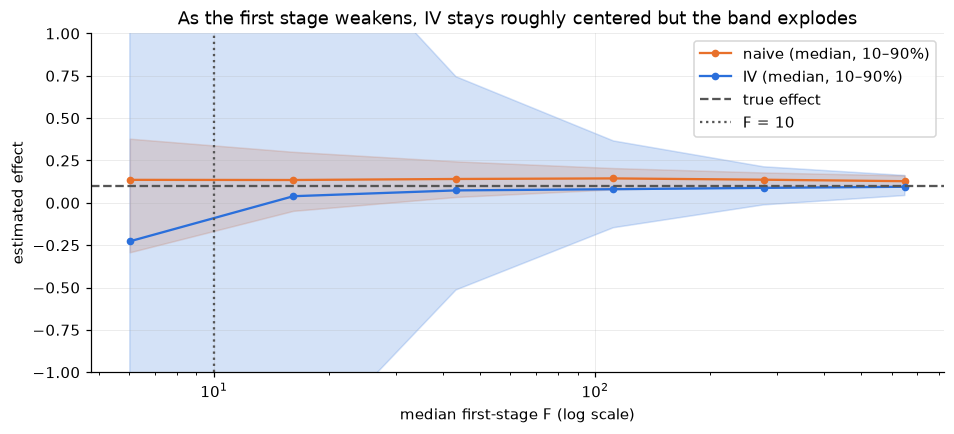

In [12]:
fig, ax = plt.subplots()
ax.fill_between(weak.F, weak.naive_p10, weak.naive_p90, color=TREATED_C, alpha=0.2)
ax.plot(weak.F, weak.naive_median, "o-", color=TREATED_C, label="naive (median, 10–90%)")
ax.fill_between(weak.F, weak.iv_p10, weak.iv_p90, color=CONTROL_C, alpha=0.2)
ax.plot(weak.F, weak.iv_median, "o-", color=CONTROL_C, label="IV (median, 10–90%)")
ax.axhline(TAU, color=GREY, ls="--", label="true effect")
ax.axvline(10, color=GREY, ls=":", label="F = 10")
ax.set_xscale("log"); ax.set_ylim(-1.0, 1.0)
ax.set_xlabel("median first-stage F (log scale)")
ax.set_ylabel("estimated effect")
ax.set_title("As the first stage weakens, IV stays roughly centered but the band explodes")
ax.legend()
plt.show()

Two things to read off this. First, F above 10 is a minimum, not a guarantee of a useful estimate:
at F around 40 the band still runs from about -0.5 to +0.7, so the standard error is what tells you
whether the number says anything. Second, at F of 16 and below the band is wider than any plausible
effect, and the medians wander because only a few dozen runs picked X. (The plot is cut at ±1 so the
better settings stay visible; the table has the full range.) Naive stays put and stays biased: it doesn't
use the first stage, so it doesn't feel it. That is why the weak flag matters: without it, a rarely-picked
card would get a huge, noisy IV number that could look like a finding.

## 6. Confounding strength

Turn the confounding up and down through `skill_on_win`, how much skill helps winning on its own.
At 0, skill is not a confounder and the naive estimate should be fine.

In [13]:
rows = []
for s in [0, 0.02, 0.05, 0.08, 0.12]:
    r = replicate(200, n=20_000, skill_on_win=s)
    rows.append(dict(skill_on_win=s, naive=r.naive.mean(), iv=r.iv.mean()))
conf = pd.DataFrame(rows)
conf["naive_bias"] = conf.naive - TAU
conf["iv_bias"] = conf.iv - TAU
display(conf.round(4))

,skill_on_win,naive,iv,naive_bias,iv_bias
0,0.00,0.1000,0.1028,0.0000,0.0028
1,0.02,0.1128,0.1027,0.0128,0.0027
2,0.05,0.1322,0.1028,0.0322,0.0028
3,0.08,0.1514,0.1019,0.0514,0.0019
4,0.12,0.1770,0.1015,0.0770,0.0015


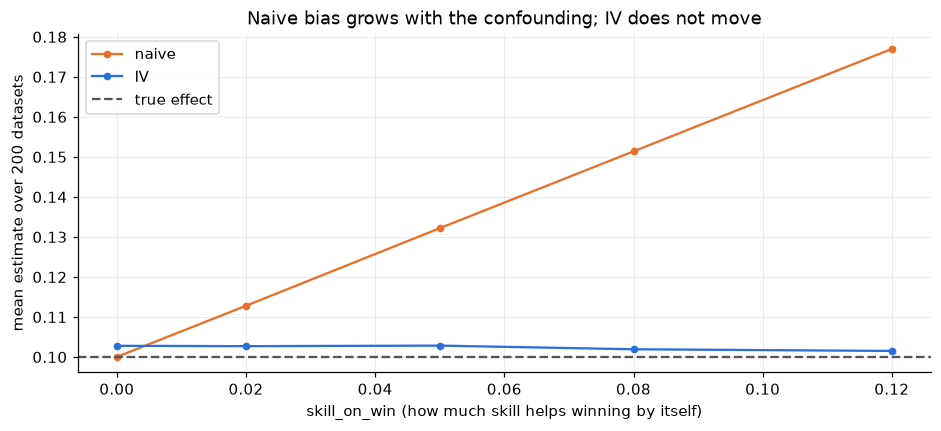

In [14]:
fig, ax = plt.subplots()
ax.plot(conf.skill_on_win, conf.naive, "o-", color=TREATED_C, label="naive")
ax.plot(conf.skill_on_win, conf.iv, "o-", color=CONTROL_C, label="IV")
ax.axhline(TAU, color=GREY, ls="--", label="true effect")
ax.set_xlabel("skill_on_win (how much skill helps winning by itself)")
ax.set_ylabel("mean estimate over 200 datasets")
ax.set_title("Naive bias grows with the confounding; IV does not move")
ax.legend()
plt.show()

With no confounding, naive and IV agree. As skill matters more for winning, naive drifts up in a
straight line and IV stays on 0.10. IV doesn't need to know how strong the confounding is or
measure it, which is its main use here: skill can't be measured.

## 7. When the instrument breaks

IV is only as good as its assumptions. Two of them can fail, and both are worth understanding
because they map onto concerns in the Spirometry design.

**Independence fails** (`offer_skill = 0.5`): skilled runs are offered X more often. This happens in
real data if the offer depends on how the run went earlier: a run that survives to later screens, or
one that takes an elite early and gets rarer cards, is not a random draw of players. The offer now
carries skill, so IV inherits the bias.

**Exclusion fails** (`direct = 0.03`): being offered X changes the win probability even if the run
doesn't take it. The IV then credits the card with that direct effect, scaled up by the first stage:
bias ≈ `direct / first stage`.

In [15]:
cases = {"clean": {},
         "offer depends on skill": dict(offer_skill=0.5),
         "offer acts on winning directly": dict(direct=0.03)}
rows = []
for name, kw in cases.items():
    r = replicate(200, n=20_000, **kw)
    rows.append(dict(case=name, naive=r.naive.mean(), iv=r.iv.mean(), first_stage=r.first_stage.mean()))
broken = pd.DataFrame(rows).set_index("case")
broken["iv_bias"] = broken.iv - TAU
broken["predicted_bias_direct"] = np.nan
broken.loc["offer acts on winning directly", "predicted_bias_direct"] = (
    0.03 / broken.loc["offer acts on winning directly", "first_stage"])
display(broken.round(4))

d_skew = simulate(n=200_000, offer_skill=0.5, seed=5)
print("\nbalance check when independence fails:")
print("mean skill, not offered vs offered:", d_skew.groupby("offered").skill.mean().round(3).tolist())

,naive,iv,first_stage,iv_bias,predicted_bias_direct
case,,,,,
clean,0.1322,0.1028,0.3029,0.0028,NaN
offer depends on skill,0.1463,0.1663,0.3632,0.0663,NaN
offer acts on winning directly,0.1552,0.2021,0.3029,0.1021,0.099



balance check when independence fails:
mean skill, not offered vs offered: [-0.146, 0.332]


Both failures move IV far from 0.10, and in the second case the predicted bias matches the simulated
one. In the first case IV ends up further from the truth than naive, so IV is not a safe default: it is
only better when its assumptions hold. Independence is the one we can partly check in real data: a balance table like the one in
section 2, on things fixed before the offer, would show a problem. Exclusion can't be tested. It has
to be argued: seeing a card and passing on it should not change how the run goes.

The independence failure is why the wins tooling uses only the **first 3 reward screens**: by then
few runs have died, so a run that reaches screen 3 is close to a random draw of players. Over a whole
run, survival makes the offer depend on skill (the synthetic "ever offered" test in PR #12 shows this). It is also
why `screen_mix` is worth reporting: taking an elite early is a player's choice, and elites
change what gets offered.

## 8. Who the IV estimate is about

So far the card helps everyone by exactly 0.10. Suppose it helps skilled players more:
the effect for a run is `tau + het * skill`. IV then recovers the average effect **among the runs
whose picking the offer changed**, which here are the runs that pick X when offered (nobody can pick a card they
weren't offered). Those runs are more skilled than average, so the number is not the average effect
over all players.

In [16]:
d_het = simulate(n=200_000, het=0.05, seed=3)
e = estimates(d_het)
het_tab = pd.Series({
    "IV estimate": e["iv"],
    "true average effect, among runs that picked X": d_het.effect_i[d_het.picked == 1].mean(),
    "true average effect, among all runs": d_het.effect_i.mean(),
}, name="effect")
display(het_tab.round(4).to_frame())

,effect
IV estimate,0.1332
"true average effect, among runs that picked X",0.1293
"true average effect, among all runs",0.1000


IV lands (within noise) on the effect for the pickers, not on the population average of 0.10. For a game
question that is usually the useful group (the players who take the card), but it has to be said
correctly: "among runs that take the card when it's offered", not "for every player".

The second caveat is about what the comparison is *against*. In the real data, a run that picks
X didn't pick the other cards on that screen, so the effect is X versus whatever else that run would have taken.

## 9. Mapping back to Spirometry

| what this notebook showed | where it shows up in the design |
|---|---|
| Naive compares players, not cards | why the win effect uses the offer rather than pick vs. no pick |
| ITT is clean, IV rescales it | `wins.itt`, `wins.first_stage`, `wins.iv`; the IV is ITT / first stage |
| Weak first stage makes IV noisy | the `F < 10` weak flag; expect it on rarely-picked cards |
| Independence can fail through survival and screen type | first 3 screens only; the `screen_mix` option |
| Exclusion can't be tested | an assumption to state in the write-up |
| IV is about the pickers, and X versus the alternatives | wording for the results and for interviews |

Things to say in an interview, in plain terms:

- The naive comparison is confounded because skilled players both pick good cards and win more.
- The offer is random and only matters for winning through the pick, so it isolates the part of
  picking that has nothing to do with skill.
- The price is variance, and a weak-instrument check tells you when the estimate is too noisy to read.
- The estimate is for players who take the card when it's offered, versus the alternatives they had.